In [11]:
import pandas as pd

In [12]:
data=pd.read_csv('Real estate valuation data set.csv')

In [13]:
data

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.917,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.917,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833,5.0,390.56840,5,24.97937,121.54245,43.1
...,...,...,...,...,...,...,...,...
409,410,2013.000,13.7,4082.01500,0,24.94155,121.50381,15.4
410,411,2012.667,5.6,90.45606,9,24.97433,121.54310,50.0
411,412,2013.250,18.8,390.96960,7,24.97923,121.53986,40.6
412,413,2013.000,8.1,104.81010,5,24.96674,121.54067,52.5


In [14]:
data=data.drop(columns=['No'])

In [15]:
#separation of features and target
X=data.drop(columns=['Y house price of unit area'])
y=data['Y house price of unit area']

In [16]:
from sklearn.model_selection import train_test_split
X_train,X_val_test,y_train,y_val_test=train_test_split(X,y,test_size=0.2,random_state=42)
X_val,X_test,y_val,y_test=train_test_split(X_val_test,y_val_test,test_size=0.5,random_state=42)

In [17]:
feature_names=X_train.columns

In [18]:
from sklearn.preprocessing import StandardScaler

standard_scaler=StandardScaler()
X_train=standard_scaler.fit_transform(X_train)
X_val=standard_scaler.transform(X_val)
X_test=standard_scaler.transform(X_test)

In [19]:
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor,plot_tree
from sklearn.metrics import root_mean_squared_error

decision_tree_regressor=DecisionTreeRegressor(criterion='squared_error',max_depth=3,random_state=42)
decision_tree_regressor.fit(X_train,y_train)
y_pred=decision_tree_regressor.predict(X_test)
print('Decision Tree Regressor RMSE:',root_mean_squared_error(y_test,y_pred))

Decision Tree Regressor RMSE: 6.23646202921134


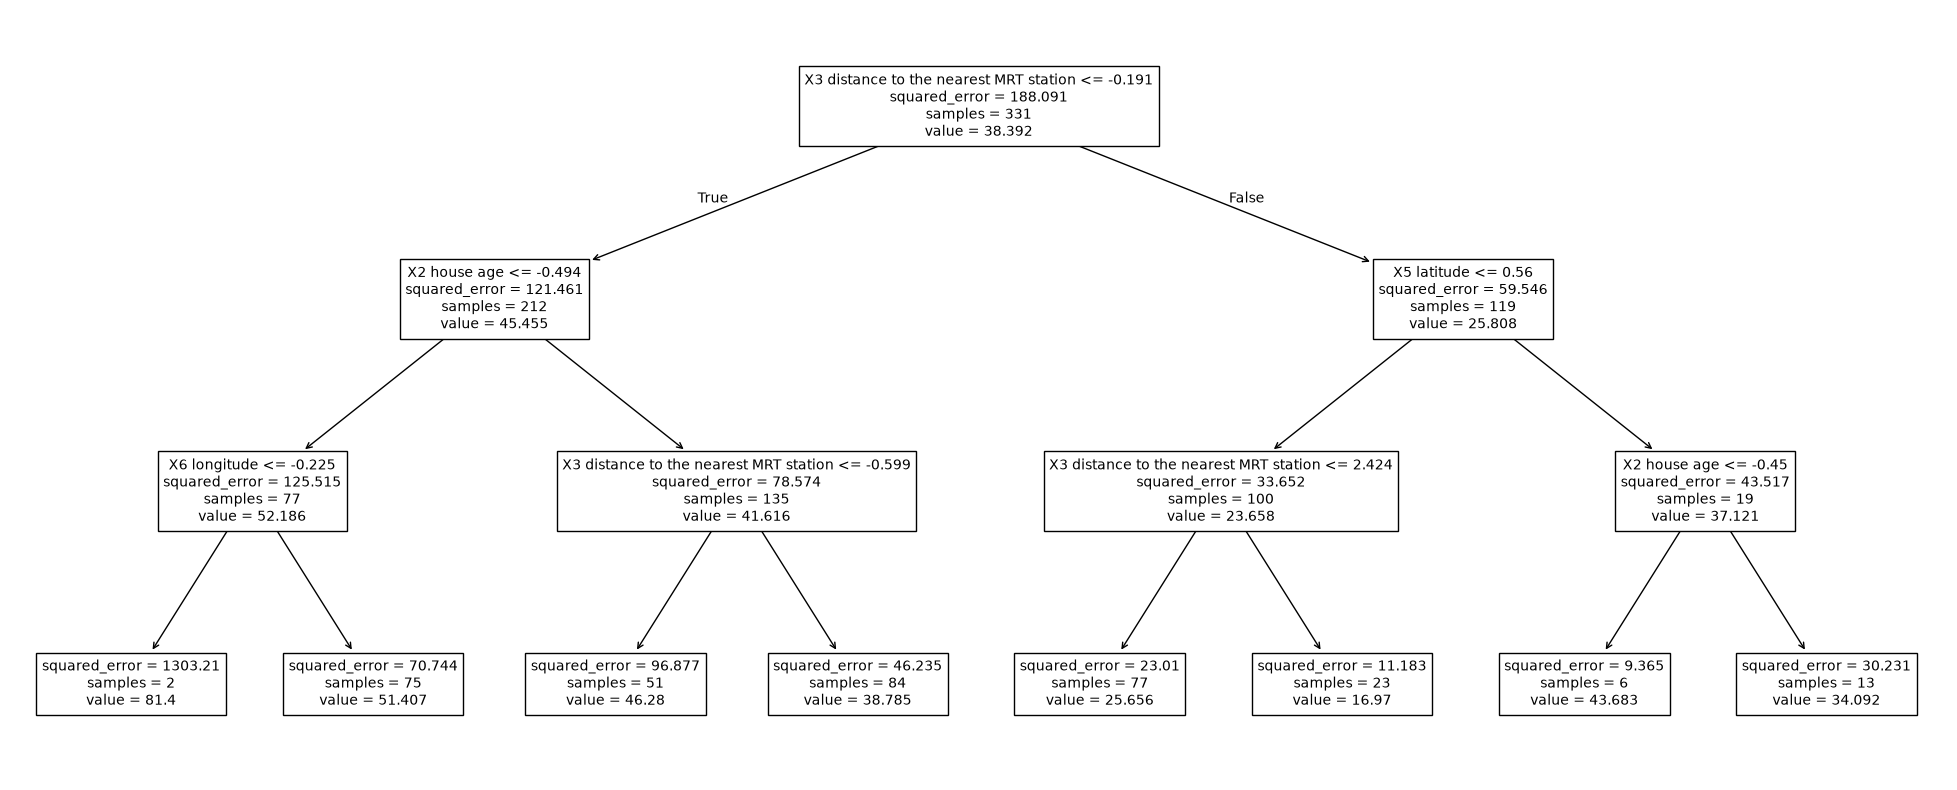

In [20]:
plt.figure(figsize=(25,10))
plot_tree(decision_tree_regressor,feature_names=feature_names,fontsize=10)
plt.show()